# Task 3: Knockout Perturbation Delta Modeling (`WT → Mab21l2_KO`) | 基因敲除扰动 Delta 预测实战

**T3 核心难点 / Core Challenge of Task 3**:

Task 3 requires predicting both **transcriptional shift** and **3D morphogenesis changes** under genetic knockouts (`Mab21l2`, `Gata4`, `Ctnnb1`). Because cell types respond unevenly to perturbations—and rare populations suffer high variance—we demonstrate a **shrinkage cell-type perturbation delta estimator** (`shrink * Δ_celltype + (1 - shrink) * Δ_global`) coupled with 3D spatial scaling, evaluated on an isolated holdout fold.


In [1]:
import json, sys, tempfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / "vec_nb_helpers.py").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

from vec_nb_helpers import (
    SPATIAL_KEY,
    _dense_float,
    check_submission_contract,
    load_task_pair,
    predict_celltype_perturbation_delta,
    predict_pseudobulk_shift,
    score_with_veckit_optional,
)

wt, ko_full, source_tag = load_task_pair("T3")
print(f"Loaded T3 pair from: {source_tag} | WT={wt.shape}, KO={ko_full.shape}")
print("T3 genes head:", list(wt.var_names[:6]))


Loaded T3 pair from: veckit_sample:veckit | WT=(150, 500), KO=(150, 500)
T3 genes head: ['A2m', 'AI646519', 'Abca6', 'Abca8a', 'Abcc9', 'Abi3bp']


## 1. `wt_identity` 基线 vs 细胞类型收缩扰动 Delta / Identity vs Shrinkage Cell-Type Delta

这里严格将 `ko_full` 拆为 `ko_fit` 与 `ko_eval`，用 `ko_fit` 拟合每个细胞类型的扰动响应向量与 3D 空间尺度变换，并在从未参与拟合的 `ko_eval` 上对比方向一致性与显著 Marker 误差。


In [2]:
rng = np.random.default_rng(13)
perm = rng.permutation(ko_full.n_obs)
half = ko_full.n_obs // 2
ko_fit = ko_full[perm[:half]].copy()
ko_eval = ko_full[perm[half:]].copy()

pred_wt_id = predict_pseudobulk_shift(wt, np.zeros(wt.n_vars, dtype=np.float32), noise_std=0.0)
pred_ct_delta = predict_celltype_perturbation_delta(wt, ko_fit, obs_key="celltype", shrink=0.75, min_cells=5)

x_wt = _dense_float(wt)
x_eval = _dense_float(ko_eval)
x_pred = _dense_float(pred_ct_delta)

true_delta = x_eval.mean(axis=0) - x_wt.mean(axis=0)
pred_delta = x_pred.mean(axis=0) - x_wt.mean(axis=0)

sign_acc = float(np.mean(np.sign(true_delta) == np.sign(pred_delta)))
mae_wt_id = float(np.mean(np.abs(true_delta)))
mae_ct = float(np.mean(np.abs(true_delta - pred_delta)))
print(f"Mean |DE| error (wt_identity)       : {mae_wt_id:.4f}")
print(f"Mean |DE| error (celltype_delta_pred): {mae_ct:.4f}")
print(f"DE sign agreement vs eval knockout   : {sign_acc:.3%}")
print("Contract check (T3 pred):", check_submission_contract(pred_ct_delta, wt, require_spatial=True))


Mean |DE| error (wt_identity)       : 0.1922
Mean |DE| error (celltype_delta_pred): 0.1317
DE sign agreement vs eval knockout   : 72.800%
Contract check (T3 pred): {'ok': True, 'n_obs': 150, 'n_vars': 500, 'var_names_exact_match': True, 'non_negative': True, 'all_finite': True, 'spatial_3D_valid': True}


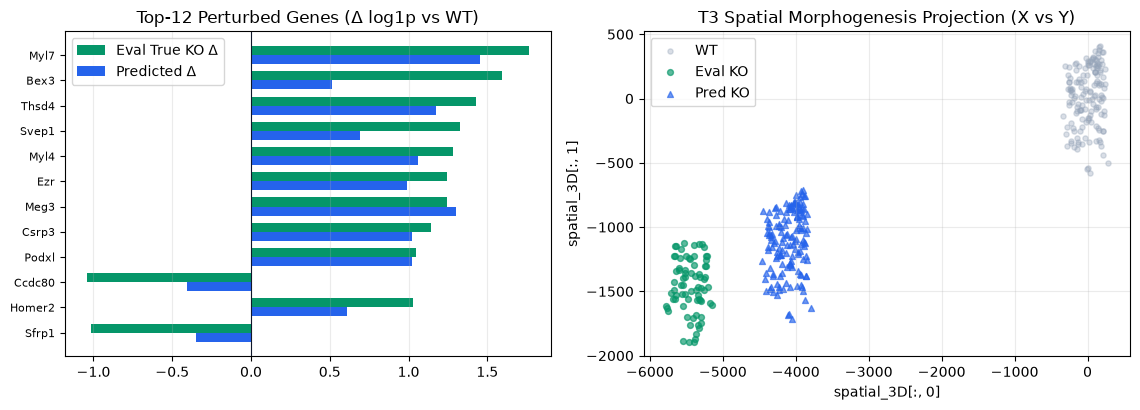

/Users/xinorigin/.cache/uv/archive-v0/XPnnoAnx1UFL1af0/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


veckit wt_identity : {
  "de_score": 0.0,
  "de_direction": 0.0,
  "severity_slope": -6.9078,
  "energy_distance": 0.96639,
  "mmd_u": 0.06732,
  "variogram": 0.032877,
  "pb_rel_err": 0.3794,
  "library_size_ratio": 1.0,
  "variance_ratio": 0.938,
  "composition_JSD": 0.0205,
  "pseudobulk_pearson": 0.8993,
  "_de_raw": 0.0,
  "_de_chance": 0.1154,
  "_n_up": 22,
  "_n_dn": 4,
  "_slope_r2": 0.0,
  "d2_shape": 0.01743,
  "sliced_wasserstein": 0.06923,
  "occupancy_dice": 0.384,
  "scale_log_ratio": 0.1613,
  "count_log_ratio": 0.6931,
  "neighborhood_mmd": 0.12929,
  "_sw_flip_spread": 0.0104,
  "_dice_voxel_over_nn": 1.4
}
veckit ct_delta    : {
  "de_score": 0.6087,
  "de_direction": 0.6412,
  "severity_slope": -0.3655,
  "energy_distance": 0.17353,
  "mmd_u": 0.06309,
  "variogram": 0.069312,
  "pb_rel_err": 0.2327,
  "library_size_ratio": 1.07,
  "variance_ratio": 0.891,
  "composition_JSD": 0.012,
  "pseudobulk_pearson": 0.9623,
  "_de_raw": 0.6538,
  "_de_chance": 0.1154,
  "_n_

/Users/xinorigin/.cache/uv/archive-v0/XPnnoAnx1UFL1af0/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Panel A: Top-12 perturbed genes comparison (True delta vs Predicted delta)
top12 = np.argsort(np.abs(true_delta))[-12:][::-1]
y = np.arange(len(top12))
names = [str(wt.var_names[i]) for i in top12]
axes[0].barh(y - 0.18, true_delta[top12], height=0.36, label="Eval True KO Δ", color="#059669")
axes[0].barh(y + 0.18, pred_delta[top12], height=0.36, label="Predicted Δ", color="#2563eb")
axes[0].axvline(0.0, color="#0f172a", lw=0.8)
axes[0].set_yticks(y)
axes[0].set_yticklabels(names, fontsize=8)
axes[0].invert_yaxis()
axes[0].set_title("Top-12 Perturbed Genes (Δ log1p vs WT)")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.25)

# Panel B: 3D spatial comparison WT vs KO eval vs Predicted
s_wt = np.asarray(wt.obsm[SPATIAL_KEY])
s_eval = np.asarray(ko_eval.obsm[SPATIAL_KEY])
s_pred = np.asarray(pred_ct_delta.obsm[SPATIAL_KEY])
axes[1].scatter(s_wt[:, 0], s_wt[:, 1], s=14, alpha=0.35, label="WT", color="#94a3b8")
axes[1].scatter(s_eval[:, 0], s_eval[:, 1], s=18, alpha=0.65, label="Eval KO", color="#059669")
axes[1].scatter(s_pred[:, 0], s_pred[:, 1], s=18, alpha=0.65, marker="^", label="Pred KO", color="#2563eb")
axes[1].set_title("T3 Spatial Morphogenesis Projection (X vs Y)")
axes[1].set_xlabel("spatial_3D[:, 0]")
axes[1].set_ylabel("spatial_3D[:, 1]")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

with tempfile.TemporaryDirectory() as tmp:
    tmp_p = Path(tmp)
    p_wt, p_tgt = tmp_p / "wt.h5ad", tmp_p / "tgt.h5ad"
    p_id, p_ct = tmp_p / "wt_id.h5ad", tmp_p / "ct_delta.h5ad"
    wt.write_h5ad(p_wt)
    ko_eval.write_h5ad(p_tgt)
    pred_wt_id.write_h5ad(p_id)
    pred_ct_delta.write_h5ad(p_ct)
    s_id = score_with_veckit_optional("T3", p_id, p_tgt, p_wt)
    s_ct = score_with_veckit_optional("T3", p_ct, p_tgt, p_wt)
    if s_id and s_ct:
        print("veckit wt_identity :", json.dumps(s_id["metrics"], indent=2))
        print("veckit ct_delta    :", json.dumps(s_ct["metrics"], indent=2))
